Cross-league analysis (pooled calibration, liquidity & timing, trading rules)

Reads the per-league outputs of `full_league_analysis.ipynb` (via `run_all_leagues.ipynb`) in `results/full/<league>/` -> produces every pooled nb used in the report. No re-download here, per-league results unchanged.

1. Sample + validation: per-league nbs recomputed here must = the saved ones.
2. Calibration: pooled reliability diagram, pooled calibration slope, outcome gaps, heterogeneity across leagues.
3. Forecast skill by league + paired 1d vs 7d comparison.
4. Deviations from the no-arbitrage identity: time to kickoff, spread, volume, league.
5. 27 simple trading rules w/ Holm corrections, + global Holm correction of the 72 calibration tests.

All CIs resample whole matches (cluster bootstrap, B = 1000).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from cycler import cycler
from scipy.stats import norm, chi2

PROJECT = (Path.cwd().parent if Path.cwd().name == "src" else Path.cwd())  # project folder
RESULTS_ROOT = PROJECT / "results" / "full"
OUT = PROJECT / "results" / "cross_league"
OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT / "images"  # all figs from all notebooks go here
FIG_DIR.mkdir(parents=True, exist_ok=True)

LEAGUE_NAMES = {"epl": "Premier League", "laliga": "La Liga", "bundesliga": "Bundesliga", "seriea": "Serie A",
                "ligue1": "Ligue 1", "eredivisie": "Eredivisie", "ligamx": "Liga MX", "brasileiro": "Brasileirão",
                "ucl": "Champions League"}
LEAGUES = [l for l in LEAGUE_NAMES if (RESULTS_ROOT / l / "analysis_ready.csv").is_file()]
assert len(LEAGUES) == 9, f"expected 9 leagues, found {LEAGUES}"
LEGS = ["home", "draw", "away"]
FEE_RATE = 0.07
B = 1000
SEED = 456
BINS = np.linspace(0, 1, 11)

MIT ={"mit_red": "#750014", "red": "#A31F34", "light_red": "#D98C97", "bright_red": "#FF1423",
       "silver": "#8B959E", "dark_gray": "#626A73", "light_gray": "#B8C2CC", "black": "#212326"}
MIT_CYCLE = [MIT[k] for k in ["mit_red", "silver", "light_red", "dark_gray", "red", "light_gray", "black"]]
HORIZON_COLORS = {"1d": MIT["mit_red"], "7d": MIT["silver"]}
mpl.rcParams.update({
    "axes.prop_cycle": cycler(color=MIT_CYCLE),
    "axes.edgecolor": MIT["dark_gray"], "axes.labelcolor": MIT["black"], "text.color": MIT["black"],
    "xtick.color": MIT["dark_gray"], "ytick.color": MIT["dark_gray"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": MIT["light_gray"], "grid.alpha": 0.6, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})
def save_fig(name):
    for ext in ("png", "pdf"):
        plt.savefig(FIG_DIR / f"{name}.{ext}")
pd.set_option("display.width", 220)
print("Leagues:", [LEAGUE_NAMES[l] for l in LEAGUES])

Leagues: ['Premier League', 'La Liga', 'Bundesliga', 'Serie A', 'Ligue 1', 'Eredivisie', 'Liga MX', 'Brasileirão', 'Champions League']


In [2]:
logit = lambda p: np.log(np.clip(p, 1e-8, 1 - 1e-8) / (1 - np.clip(p, 1e-8, 1 - 1e-8)))

def fit_logit(x, y, w=None, iters=50):
    # (weighted) logit reg of y on [1, x] via Newton-Raphson, w = freq weights -> returns (a, b)
    w = np.ones_like(x) if w is None else w
    Z = np.column_stack([np.ones_like(x), x])
    beta = np.zeros(2)
    for _ in range(iters):
        mu = 1 / (1 + np.exp(-Z @ beta))
        step = np.linalg.solve(Z.T @ (Z * (w * mu * (1 - mu))[:, None]), Z.T @ (w * (y - mu)))
        beta += step
        if np.abs(step).max() < 1e-10:
            break
    return beta

def match_weights(n_matches, B=B, seed=SEED):
    # B x M matrix: how many times each match is drawn in each resample (cluster bootstrap)
    picks = np.random.default_rng(seed).integers(0, n_matches, (B, n_matches))
    return np.stack([np.bincount(p, minlength=n_matches) for p in picks])

def holm(p, alpha=0.05):
    # Holm step-down rejections + adjusted p-values
    p = np.asarray(p, float); m = len(p); order = np.argsort(p)
    adj = np.empty(m); running = 0.0
    for j, i in enumerate(order):
        running = max(running, (m - j) * p[i]); adj[i] = min(1.0, running)
    return adj <= alpha, adj

def ci(boot):
    return np.percentile(boot, 2.5), np.percentile(boot, 97.5)

1. Sample + validation

`long` has 1 row per match × horizon × outcome, built exactly as in the per-league notebook: midpoint `p`, result `y`, restricted to matches quoted at both horizons (so 1d and 7d compare the same games).

In [3]:
frames, wide = [], {}
for lg in LEAGUES:
    ar = pd.read_csv(RESULTS_ROOT / lg / "analysis_ready.csv")
    wide[lg] = ar
    n_h = ar.groupby("event_ticker")["horizon"].nunique()
    paired = n_h[n_h == 2].index
    d = ar[ar["event_ticker"].isin(paired)]
    for leg in LEGS:
        frames.append(pd.DataFrame({"league": lg, "event_ticker": d["event_ticker"], "horizon": d["horizon"], "leg": leg,
                                    "p": d[f"{leg}_midpoint"], "y": d[f"{leg}_won"].astype(float),
                                    "ask": d[f"{leg}_yes_ask"], "bid": d[f"{leg}_yes_bid"]}))
long = pd.concat(frames, ignore_index=True)
assert long["p"].between(0, 1, inclusive="neither").all()
assert (long.groupby(["event_ticker", "horizon"])["y"].sum() == 1).all(), "exactly one outcome per match"

# Val 1: per-league slope + draw gap recomputed here = saved per-league results
for lg in LEAGUES:
    saved = pd.read_csv(RESULTS_ROOT / lg / "calibration_regression.csv").set_index("horizon")["b"]
    mt = pd.read_csv(RESULTS_ROOT / lg / "multiple_testing.csv").set_index("test")["estimate"]
    for h in ["1d", "7d"]:
        d = long[(long["league"] == lg) & (long["horizon"] == h)]
        b = fit_logit(logit(d["p"]).values, d["y"].values)[1]
        dr = d[d["leg"] == "draw"]
        assert np.isclose(b, saved[h], atol=1e-6), (lg, h, b, saved[h])
        assert np.isclose((dr["y"] - dr["p"]).mean(), mt[f"draw gap = 0 ({h})"], atol=1e-9), (lg, h)
print("Validation: slopes and draw gaps match every league's saved results.")

# sample table
summ = pd.concat([pd.read_csv(RESULTS_ROOT / lg / "summary.csv") for lg in LEAGUES])
sample = summ.pivot(index="league", columns="horizon", values="matches").reindex(LEAGUES)
sample.columns = ["matches_1d", "matches_7d"]
sample["paired"] = long.groupby("league")["event_ticker"].nunique().reindex(LEAGUES)
sample["hourly_complete_hours"] = summ.drop_duplicates("league").set_index("league")["hourly_complete_rows"].reindex(LEAGUES)
sample.loc["total"] = sample.sum()
sample.index = [LEAGUE_NAMES.get(i, "Total") for i in sample.index]
print(sample.astype(int).to_string())

Validation: slopes and draw gaps match every league's saved results.
                  matches_1d  matches_7d  paired  hourly_complete_hours
Premier League           485         480     478                  85079
La Liga                  489         459     454                  77778
Bundesliga               387         383     383                  60603
Serie A                  485         468     465                  76122
Ligue 1                  395         380     379                  57972
Eredivisie               325         134     134                  28077
Liga MX                  327         140     137                  33230
Brasileirão              410         370     357                  53166
Champions League         353         253     253                  50389
Total                   3656        3067    3040                 522416


2. Calibration across all leagues

Calibration slope: logit reg of the outcome on the log-odds of the price, $\Pr(y=1)=\Lambda(a+b\,\mathrm{logit}\,p)$. Perfect calibration -> $a=0,\ b=1$; $b<1$ = prices too extreme (favourites overpriced, long shots underpriced), $b>1$ too timid. \
Outcome gap = realized freq − avg price for home, draw & away. \
Heterogeneity: Cochran's $Q=\sum_\ell (\hat\theta_\ell-\bar\theta)^2/\mathrm{se}_\ell^2$ tests whether the 9 leagues share 1 value ($\chi^2_8$ under the null).

In [4]:
def pooled_calibration(d, wts):
    # point estimate + cluster-bootstrap draws of (a, b), w/ match freq weights
    codes, uniq = pd.factorize(d["event_ticker"])
    x, y = logit(d["p"]).values, d["y"].values
    a, b = fit_logit(x, y)
    W = match_weights(len(uniq)) if wts is None else wts
    boot = np.array([fit_logit(x, y, w=W[k][codes].astype(float)) for k in range(len(W))])
    return a, b, boot, codes, W

pool_rows, rel_rows, gap_rows = [], [], []
for h in ["1d", "7d"]:
    d = long[long["horizon"] == h].reset_index(drop=True)
    a, b, boot, codes, W = pooled_calibration(d, None)
    se_b = boot[:, 1].std()
    pool_rows.append({"horizon": h, "matches": d["event_ticker"].nunique(), "forecasts": len(d),
                      "a": a, "a_ci": "[%.3f, %.3f]" % ci(boot[:, 0]), "b": b, "b_ci": "[%.3f, %.3f]" % ci(boot[:, 1]),
                      "p(b=1)": 2 * norm.sf(abs((b - 1) / se_b))})
    # reliability table w/ cluster-bootstrap CIs per bin
    bin_id = pd.cut(d["p"], BINS, include_lowest=True, labels=False).values
    for k in range(len(BINS) - 1):
        m = bin_id == k
        if not m.any():
            continue
        n_m = np.bincount(codes[m], minlength=W.shape[1]); y_m = np.bincount(codes[m], weights=d["y"].values[m], minlength=W.shape[1])
        p_m = np.bincount(codes[m], weights=d["p"].values[m], minlength=W.shape[1])
        f_boot = (W @ y_m) / np.maximum(W @ n_m, 1)
        lo, hi = ci(f_boot)
        rel_rows.append({"horizon": h, "bin": f"{BINS[k]:.1f}-{BINS[k+1]:.1f}", "n": int(m.sum()),
                         "avg_price": p_m.sum() / n_m.sum(), "freq_yes": y_m.sum() / n_m.sum(), "ci_low": lo, "ci_high": hi})
    # pooled outcome gaps
    for leg in LEGS:
        m = (d["leg"] == leg).values
        g = np.bincount(codes[m], weights=(d["y"] - d["p"]).values[m], minlength=W.shape[1])
        n = np.bincount(codes[m], minlength=W.shape[1])
        boot_g = (W @ g) / (W @ n)
        est = g.sum() / n.sum()
        gap_rows.append({"horizon": h, "leg": leg, "avg_price": d.loc[m, "p"].mean(), "freq": d.loc[m, "y"].mean(),
                         "gap": est, "ci_low": ci(boot_g)[0], "ci_high": ci(boot_g)[1], "p_value": 2 * norm.sf(abs(est / boot_g.std()))})

pooled_cal = pd.DataFrame(pool_rows); pooled_rel = pd.DataFrame(rel_rows); pooled_gaps = pd.DataFrame(gap_rows)
pooled_rel["price_in_ci"] = pooled_rel["avg_price"].between(pooled_rel["ci_low"], pooled_rel["ci_high"])
print("Pooled calibration regression (all nine leagues):"); print(pooled_cal.round(4).to_string(index=False))
print("\nPooled outcome gaps (realized frequency - average price):"); print(pooled_gaps.round(4).to_string(index=False))
print("\nPooled reliability table:"); print(pooled_rel.round(3).to_string(index=False))

Pooled calibration regression (all nine leagues):
horizon  matches  forecasts       a            a_ci      b           b_ci  p(b=1)
     1d     3040       9120  0.0220 [-0.028, 0.080] 1.0349 [0.957, 1.126]  0.4185
     7d     3040       9120 -0.0058 [-0.056, 0.051] 1.0233 [0.943, 1.114]  0.5835

Pooled outcome gaps (realized frequency - average price):
horizon  leg  avg_price   freq     gap  ci_low  ci_high  p_value
     1d home     0.4483 0.4523  0.0040 -0.0120   0.0217   0.6358
     1d draw     0.2420 0.2438  0.0017 -0.0140   0.0179   0.8303
     1d away     0.3099 0.3039 -0.0060 -0.0222   0.0087   0.4470
     7d home     0.4418 0.4523  0.0105 -0.0058   0.0288   0.2208
     7d draw     0.2525 0.2438 -0.0088 -0.0245   0.0075   0.2831
     7d away     0.3177 0.3039 -0.0137 -0.0299   0.0010   0.0856

Pooled reliability table:
horizon     bin    n  avg_price  freq_yes  ci_low  ci_high  price_in_ci
     1d 0.0-0.1  325      0.073     0.071   0.045    0.100         True
     1d 0.1-0.2 142

In [5]:
# per-league calibration table + heterogeneity across leagues (uses each league's saved estimates & bootstrap SEs)
rows = []
for lg in LEAGUES:
    cr = pd.read_csv(RESULTS_ROOT / lg / "calibration_regression.csv").set_index("horizon")
    mt = pd.read_csv(RESULTS_ROOT / lg / "multiple_testing.csv").set_index("test")
    sk = pd.read_csv(RESULTS_ROOT / lg / "benchmark_skill.csv").set_index("horizon")
    for h in ["1d", "7d"]:
        g = mt.loc[f"draw gap = 0 ({h})"]
        rows.append({"league": LEAGUE_NAMES[lg], "horizon": h, "slope_b": cr.loc[h, "b"], "se_b": cr.loc[h, "se_b"],
                     "b_ci": cr.loc[h, "b_95CI"], "draw_gap": g["estimate"], "se_gap": g["se"],
                     "skill_BSS": sk.loc[h, "BSS"], "skill_gain_ci": f"[{sk.loc[h, 'gain_ci_low']:.3f}, {sk.loc[h, 'gain_ci_high']:.3f}]",
                     "skill_significant": sk.loc[h, "gain_ci_low"] > 0, "benchmark_matches": int(sk.loc[h, "matches"])})
by_league = pd.DataFrame(rows)

het = []
for h in ["1d", "7d"]:
    t = by_league[by_league["horizon"] == h]
    for est, se, name, null in [("slope_b", "se_b", "calibration slope", 1.0), ("draw_gap", "se_gap", "draw gap", 0.0)]:
        w = 1 / t[se] ** 2
        mean_w = (w * t[est]).sum() / w.sum()
        Q = (w * (t[est] - mean_w) ** 2).sum()
        het.append({"horizon": h, "quantity": name, "inverse-variance mean": mean_w, "se": np.sqrt(1 / w.sum()),
                    "Q": Q, "df": len(t) - 1, "p_heterogeneity": chi2.sf(Q, len(t) - 1)})
heterogeneity = pd.DataFrame(het)
print(by_league.round(3).to_string(index=False))
print("\nDo the nine leagues share one slope / draw gap? (Cochran's Q)")
print(heterogeneity.round(4).to_string(index=False))

          league horizon  slope_b  se_b         b_ci  draw_gap  se_gap  skill_BSS   skill_gain_ci  skill_significant  benchmark_matches
  Premier League      1d    0.849 0.096 [0.68, 1.05]     0.033   0.020      0.068  [0.021, 0.070]               True                428
  Premier League      7d    0.848 0.098 [0.66, 1.06]     0.034   0.020      0.070  [0.021, 0.073]               True                426
         La Liga      1d    1.229 0.119 [1.01, 1.47]    -0.009   0.020      0.120  [0.050, 0.103]               True                412
         La Liga      7d    1.216 0.119 [1.00, 1.46]    -0.014   0.020      0.102  [0.037, 0.091]               True                397
      Bundesliga      1d    1.093 0.133 [0.86, 1.37]     0.012   0.021      0.128  [0.054, 0.110]               True                332
      Bundesliga      7d    1.110 0.131 [0.87, 1.38]     0.005   0.021      0.119  [0.049, 0.105]               True                329
         Serie A      1d    1.101 0.118 [0.88, 1

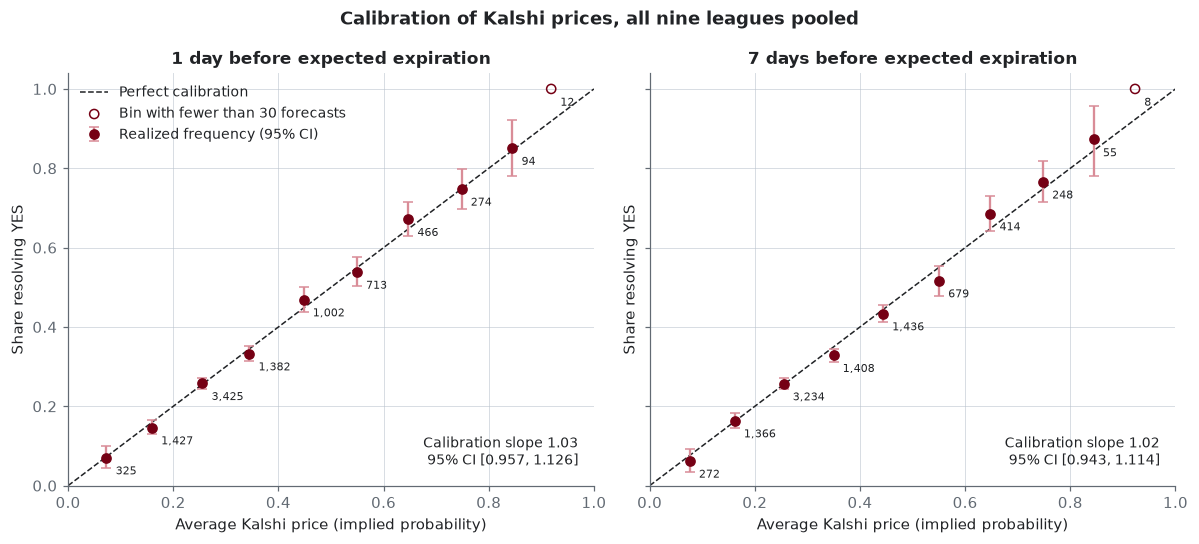

In [6]:
# fig: pooled reliability diagram
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, h in zip(axes, ["1d", "7d"]):
    t = pooled_rel[pooled_rel["horizon"] == h]
    ax.plot([0, 1], [0, 1], "--", color=MIT["black"], lw=1, label="Perfect calibration")
    big, small = t[t["n"] >= 30], t[t["n"] < 30]  # bins w/ < 30 forecasts: hollow, no CI
    ax.errorbar(big["avg_price"], big["freq_yes"], yerr=[big["freq_yes"] - big["ci_low"], big["ci_high"] - big["freq_yes"]],
                fmt="o", color=MIT["mit_red"], ecolor=MIT["light_red"], capsize=3, label="Realized frequency (95% CI)")
    ax.scatter(small["avg_price"], small["freq_yes"], facecolors="none", edgecolors=MIT["mit_red"], zorder=3,
               label="Bin with fewer than 30 forecasts")
    for _, r in t.iterrows():
        ax.annotate(f"{r['n']:,}", (r["avg_price"], r["freq_yes"]), xytext=(6, -11), textcoords="offset points", fontsize=7.5)
    b = pooled_cal.set_index("horizon").loc[h]
    ax.set_title(f"{'1 day' if h == '1d' else '7 days'} before expected expiration")
    ax.text(0.97, 0.04, f"Calibration slope {b['b']:.2f}\n95% CI {b['b_ci']}", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
    ax.set_xlabel("Average Kalshi price (implied probability)")
    ax.set_ylabel("Share resolving YES")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.04)
axes[0].legend(loc="upper left")
fig.suptitle("Calibration of Kalshi prices, all nine leagues pooled", fontweight="bold")
plt.tight_layout(); save_fig("cross_league_reliability_diagram"); plt.show()

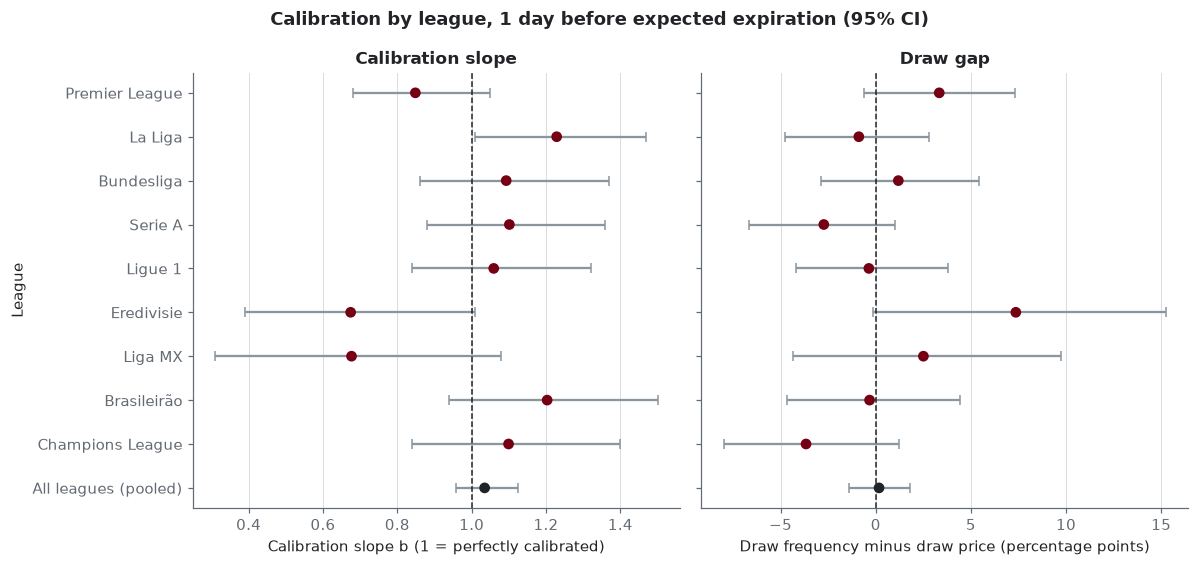

In [7]:
# fig: forest plot of calibration slope + draw gap by league (1d), w/ pooled estimate
h = "1d"
t = by_league[by_league["horizon"] == h].iloc[::-1].reset_index(drop=True)
pc = pooled_cal.set_index("horizon").loc[h]
pg = pooled_gaps[(pooled_gaps["horizon"] == h) & (pooled_gaps["leg"] == "draw")].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
y = np.arange(len(t) + 1)
labels = ["All leagues (pooled)"] + list(t["league"])

lo = [float(pc["b_ci"].strip("[]").split(",")[0])] + [float(s.strip("[]").split(",")[0]) for s in t["b_ci"]]
hi = [float(pc["b_ci"].strip("[]").split(",")[1])] + [float(s.strip("[]").split(",")[1]) for s in t["b_ci"]]
est = [pc["b"]] + list(t["slope_b"])
axes[0].errorbar(est, y, xerr=[np.array(est) - lo, np.array(hi) - est], fmt="none", ecolor=MIT["silver"], capsize=3)
axes[0].scatter(est, y, color=[MIT["black"]] + [MIT["mit_red"]] * len(t), zorder=3)
axes[0].axvline(1, color=MIT["black"], ls="--", lw=1)
axes[0].set_xlabel("Calibration slope b (1 = perfectly calibrated)")
axes[0].set_title("Calibration slope")

gest = [100 * pg["gap"]] + list(100 * t["draw_gap"])
og = {LEAGUE_NAMES[lg]: pd.read_csv(RESULTS_ROOT / lg / "outcome_gaps.csv").query("horizon == @h and leg == 'draw'").iloc[0] for lg in LEAGUES}
glo = [100 * pg["ci_low"]] + [100 * og[l]["ci_low"] for l in t["league"]]  # percentile cluster-bootstrap CIs, same as pooled row
ghi = [100 * pg["ci_high"]] + [100 * og[l]["ci_high"] for l in t["league"]]
axes[1].errorbar(gest, y, xerr=[np.array(gest) - glo, np.array(ghi) - gest], fmt="none", ecolor=MIT["silver"], capsize=3)
axes[1].scatter(gest, y, color=[MIT["black"]] + [MIT["mit_red"]] * len(t), zorder=3)
axes[1].axvline(0, color=MIT["black"], ls="--", lw=1)
axes[1].set_xlabel("Draw frequency minus draw price (percentage points)")
axes[1].set_title("Draw gap")
axes[0].set_yticks(y); axes[0].set_yticklabels(labels); axes[0].set_ylabel("League")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("Calibration by league, 1 day before expected expiration (95% CI)", fontweight="bold")
plt.tight_layout(); save_fig("cross_league_calibration_forest"); plt.show()

3. Forecast skill + paired 1d vs 7d comparison

Skill (from each league's no-look-ahead benchmark): Brier skill score vs historical outcome freqs computed only from matches settled b4 the quote. \
Horizon effect: Brier score 1d − 7d on the same matches; negative -> prices improve as kickoff approaches.

In [8]:
rows = []
allpm = []
for lg in LEAGUES:
    d = long[long["league"] == lg]
    pm = d.assign(se=(d["p"] - d["y"]) ** 2).groupby(["event_ticker", "horizon"])["se"].sum().unstack()
    diff = (pm["1d"] - pm["7d"]).values
    W = match_weights(len(diff))
    boot = (W @ diff) / len(diff)
    rows.append({"league": LEAGUE_NAMES[lg], "paired_matches": len(diff), "brier_1d": pm["1d"].mean(), "brier_7d": pm["7d"].mean(),
                 "diff_1d_minus_7d": diff.mean(), "ci_low": ci(boot)[0], "ci_high": ci(boot)[1]})
    allpm.append(diff)
diff = np.concatenate(allpm); W = match_weights(len(diff)); boot = (W @ diff) / len(diff)
rows.append({"league": "All leagues", "paired_matches": len(diff), "brier_1d": np.nan, "brier_7d": np.nan,
             "diff_1d_minus_7d": diff.mean(), "ci_low": ci(boot)[0], "ci_high": ci(boot)[1]})
horizon_cmp = pd.DataFrame(rows)
horizon_cmp["significant"] = (horizon_cmp["ci_high"] < 0) | (horizon_cmp["ci_low"] > 0)
print("Three-outcome Brier score on the same matches (negative difference = 1-day prices more accurate):")
print(horizon_cmp.round(4).to_string(index=False))

skill = by_league[["league", "horizon", "skill_BSS", "skill_gain_ci", "skill_significant", "benchmark_matches"]]
print("\nSkill vs the no-look-ahead historical benchmark (BSS > 0 = better than base rates):")
print(skill.assign(skill_BSS=100 * skill["skill_BSS"]).rename(columns={"skill_BSS": "skill_%"}).round(2).to_string(index=False))
print("\nLeagues with significant skill:", skill.groupby("horizon")["skill_significant"].sum().to_dict(), "of 9")

# favourite strength: avg favourite price 1d b4 (explains raw Brier diffs across leagues)
fav = long[long["horizon"] == "1d"].groupby(["league", "event_ticker"])["p"].max().groupby("league").mean()
print("\nAverage favourite price, 1 day before:", (100 * fav.rename(index=LEAGUE_NAMES)).round(1).sort_values().to_dict())

Three-outcome Brier score on the same matches (negative difference = 1-day prices more accurate):
          league  paired_matches  brier_1d  brier_7d  diff_1d_minus_7d  ci_low  ci_high  significant
  Premier League             478    0.6094    0.6126           -0.0032 -0.0100   0.0030        False
         La Liga             454    0.5600    0.5699           -0.0098 -0.0186  -0.0013         True
      Bundesliga             383    0.5642    0.5711           -0.0069 -0.0156   0.0014        False
         Serie A             465    0.5683    0.5768           -0.0085 -0.0176   0.0003        False
         Ligue 1             379    0.5770    0.5930           -0.0160 -0.0269  -0.0051         True
      Eredivisie             134    0.6193    0.6328           -0.0135 -0.0388   0.0122        False
         Liga MX             137    0.6395    0.6529           -0.0134 -0.0318   0.0040        False
     Brasileirão             357    0.5793    0.6085           -0.0291 -0.0452  -0.0136       

4. When do prices deviate from the no-arbitrage identity?

Midpoint deviation = $|\sum_i \mathrm{mid}_i - 1|$ in cents; executable band = $\sum_i \mathrm{ask}_i - \sum_i \mathrm{bid}_i$. \
(a) every complete pre-match hour, by days to kickoff \
(b) pooled reg of the deviation on spread, volume, OI, quote age, horizon & favourite strength, w/ league FE and match-clustered SEs \
(c) by league

In [9]:
hourly = pd.concat([pd.read_csv(RESULTS_ROOT / lg / "hourly_arbitrage.csv", usecols=["event_ticker", "sum_bid", "sum_ask", "sum_mid", "hours_to_ko", "volume",
                                                                                     "profit_buy_nofee", "profit_sell_nofee", "profit_buy", "profit_sell"]).assign(league=lg)
                    for lg in LEAGUES], ignore_index=True)
hourly["band_c"] = 100 * (hourly["sum_ask"] - hourly["sum_bid"])
hourly["dev_c"] = 100 * (hourly["sum_mid"] - 1).abs()
hourly["days"] = pd.cut(hourly["hours_to_ko"] / 24, [0, 1, 2, 3, 5, 7, 8], right=False)
hourly["traded"] = hourly["volume"] > 0
hourly["arb_nofee"] = (hourly["profit_buy_nofee"] > 0) | (hourly["profit_sell_nofee"] > 0)
hourly["arb_fee"] = (hourly["profit_buy"] > 0) | (hourly["profit_sell"] > 0)
print(f"{len(hourly):,} complete match-hours | apparent arbitrages before fees: {hourly['arb_nofee'].sum():,} "
      f"({100 * hourly['arb_nofee'].mean():.2f}%) | after fees: {hourly['arb_fee'].sum()}")

timing = hourly.groupby("days", observed=True).agg(match_hours=("band_c", "size"), median_band_c=("band_c", "median"),
                                                    mean_dev_c=("dev_c", "mean"), share_dev_over_2c=("dev_c", lambda s: (s > 2).mean()),
                                                    share_hours_traded=("traded", "mean"), arb_rate_nofee_pct=("arb_nofee", lambda s: 100 * s.mean()))
print("\nAll leagues, by days to kickoff:"); print(timing.round(3).to_string())

by_lg = hourly.groupby("league").agg(match_hours=("band_c", "size"), median_band_c=("band_c", "median"), mean_dev_c=("dev_c", "mean"),
                                      share_hours_traded=("traded", "mean"), arb_nofee=("arb_nofee", "sum"),
                                      arb_rate_nofee_pct=("arb_nofee", lambda s: 100 * s.mean()), arb_after_fees=("arb_fee", "sum")).reindex(LEAGUES)
by_lg.index = [LEAGUE_NAMES[l] for l in by_lg.index]
print("\nBy league (all pre-match hours):"); print(by_lg.round(3).to_string())

522,416 complete match-hours | apparent arbitrages before fees: 3,931 (0.75%) | after fees: 2

All leagues, by days to kickoff:
        match_hours  median_band_c  mean_dev_c  share_dev_over_2c  share_hours_traded  arb_rate_nofee_pct
days                                                                                                     
[0, 1)        81227            4.0       0.656              0.037               0.878               1.341
[1, 2)        76682            4.0       0.702              0.057               0.599               0.912
[2, 3)        72529            5.0       0.842              0.078               0.477               0.727
[3, 5)       130775            6.0       1.305              0.095               0.370               0.544
[5, 7)       123867            7.0       2.508              0.196               0.286               0.590
[7, 8)        37336           15.0       7.249              0.422               0.212               0.466

By league (all pre-matc

In [10]:
# pooled reg of midpoint deviation on liquidity + timing, league FE, match-clustered SEs
X = pd.concat([pd.read_csv(RESULTS_ROOT / lg / "liquidity_drivers.csv").assign(league=lg) for lg in LEAGUES], ignore_index=True)
drivers = ["max_spread_c", "log_volume", "log_oi", "quote_age_h", "is_7d", "fav_prob"]
FE = pd.get_dummies(X["league"], drop_first=True, dtype=float)
Z = np.column_stack([np.ones(len(X)), X[drivers].values, FE.values])
yv = X["abs_dev_c"].values
ZtZ_inv = np.linalg.pinv(Z.T @ Z)
beta = ZtZ_inv @ Z.T @ yv
u = yv - Z @ beta
S = pd.DataFrame(Z * u[:, None]).groupby(X["event_ticker"].values).sum().values
G, (n, k) = S.shape[0], Z.shape
V = (G / (G - 1)) * ((n - 1) / (n - k)) * ZtZ_inv @ (S.T @ S) @ ZtZ_inv
se = np.sqrt(np.diag(V))
names = ["const"] + drivers + [f"league: {LEAGUE_NAMES[c]}" for c in FE.columns]
liq_reg = pd.DataFrame({"coef": beta, "se": se, "t": beta / se, "p_value": 2 * norm.sf(np.abs(beta / se))}, index=names)
r2 = 1 - (u @ u) / ((yv - yv.mean()) @ (yv - yv.mean()))
print(f"|sum of midpoints - 1| in cents, {len(X):,} match-horizons, {G:,} matches, R^2 = {r2:.3f}")
print("(baseline league = " + LEAGUE_NAMES[sorted(X['league'].unique())[0]] + ")")
print(liq_reg.round(4).to_string())

# same reg league by league: spread + volume coeffs from each league's saved output
per = pd.concat({LEAGUE_NAMES[lg]: pd.read_csv(RESULTS_ROOT / lg / "liquidity_regression.csv", index_col=0).loc[["max_spread_c", "log_volume"], ["coef", "t"]].unstack()
                 for lg in LEAGUES}, axis=1).T
print("\nLeague by league (spread and volume coefficients):"); print(per.round(3).to_string())

|sum of midpoints - 1| in cents, 6,723 match-horizons, 3,683 matches, R^2 = 0.752
(baseline league = Brasileirão)
                            coef      se        t  p_value
const                     0.4116  0.1887   2.1814   0.0292
max_spread_c              0.3406  0.0092  36.9312   0.0000
log_volume                0.0485  0.0115   4.2132   0.0000
log_oi                    0.0711  0.0168   4.2268   0.0000
quote_age_h              -0.1574  0.0796  -1.9776   0.0480
is_7d                     0.0252  0.0868   0.2901   0.7718
fav_prob                 -0.4754  0.2067  -2.2998   0.0215
league: Bundesliga       -0.9090  0.1766  -5.1460   0.0000
league: Premier League   -1.3338  0.2120  -6.2919   0.0000
league: Eredivisie       -0.0975  0.2270  -0.4293   0.6677
league: La Liga          -1.1780  0.2022  -5.8268   0.0000
league: Liga MX          -0.9934  0.2617  -3.7953   0.0001
league: Ligue 1          -0.9512  0.1822  -5.2208   0.0000
league: Serie A          -1.1670  0.1817  -6.4232   0.0000
l

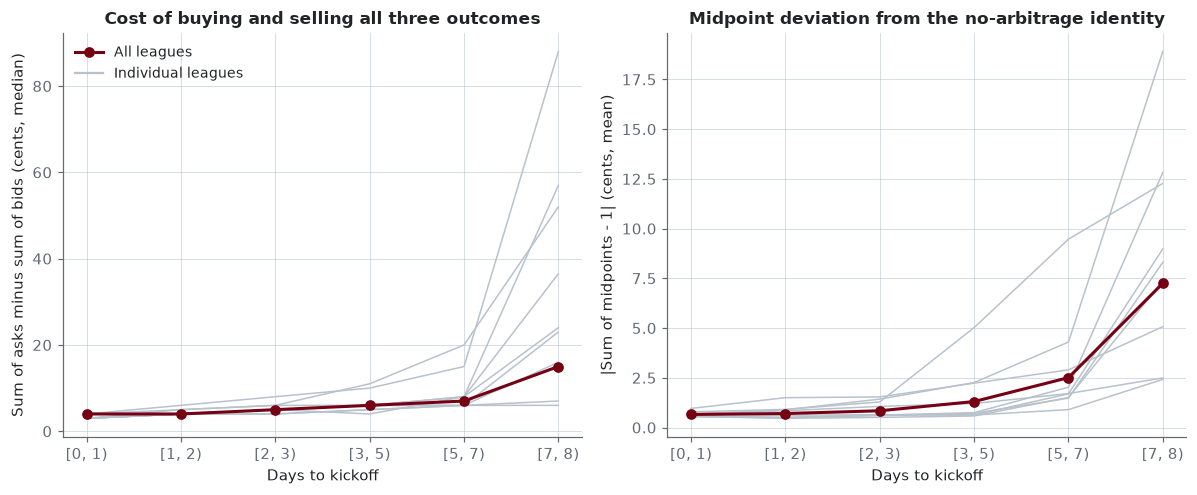

In [11]:
# fig: executable band + midpoint deviation by days to kickoff, each league & pooled
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
x = [str(i) for i in timing.index]
for lg in LEAGUES:
    t = hourly[hourly["league"] == lg].groupby("days", observed=True).agg(b=("band_c", "median"), d=("dev_c", "mean")).reindex(timing.index)
    axes[0].plot(x, t["b"], color=MIT["light_gray"], lw=1)
    axes[1].plot(x, t["d"], color=MIT["light_gray"], lw=1)
axes[0].plot(x, timing["median_band_c"], "o-", color=MIT["mit_red"], lw=2, label="All leagues")
axes[1].plot(x, timing["mean_dev_c"], "o-", color=MIT["mit_red"], lw=2, label="All leagues")
axes[0].plot([], [], color=MIT["light_gray"], label="Individual leagues")
axes[0].set_title("Cost of buying and selling all three outcomes")
axes[0].set_ylabel("Sum of asks minus sum of bids (cents, median)")
axes[1].set_title("Midpoint deviation from the no-arbitrage identity")
axes[1].set_ylabel("|Sum of midpoints - 1| (cents, mean)")
for ax in axes:
    ax.set_xlabel("Days to kickoff"); ax.tick_params(axis="x", rotation=0)
axes[0].legend()
plt.tight_layout(); save_fig("cross_league_band_by_time_to_kickoff"); plt.show()

5. Trading rules + multiple testing

27 rules: for each league & outcome (home, draw, away), buy 1 YES contract at the 1d ask in every match, pay the taker fee (0.07·P(1−P), rounded up to the cent, as in the per-league notebook) and hold to settlement. Net P&L/contract = payoff − ask − fee. Each rule takes 1 position/match -> SE is the usual one across matches. Holm corrects for testing 27 rules at once. Chronological split re-estimates each rule on the first 70% and last 30% of each league's matches.

72 calibration tests: each league's 8 tests (slope = 1 and the 3 outcome gaps = 0, at both horizons) corrected together w/ Holm.

In [12]:
def kalshi_fee(price):
    return np.ceil(np.round(100 * FEE_RATE * price * (1 - price), 10)) / 100

rows = []
for lg in LEAGUES:
    d = wide[lg][wide[lg]["horizon"] == "1d"].copy()
    d["exp_time"] = pd.to_datetime(d["scheduled_event_time"], utc=True)
    d = d.sort_values("exp_time")
    cut = int(0.7 * len(d))
    for leg in LEGS:
        ask = d[f"{leg}_yes_ask"].values
        cost = ask + kalshi_fee(ask)
        pnl = d[f"{leg}_won"].values - cost
        r = {"league": LEAGUE_NAMES[lg], "outcome": leg, "trades": len(pnl), "mean_pnl": pnl.mean(),
             "se": pnl.std(ddof=1) / np.sqrt(len(pnl)), "return_on_cost_%": 100 * pnl.sum() / cost.sum(),
             "hit_rate": d[f"{leg}_won"].mean(), "avg_ask": ask.mean()}
        r["ci_low"], r["ci_high"] = r["mean_pnl"] - 1.96 * r["se"], r["mean_pnl"] + 1.96 * r["se"]
        r["p_value"] = 2 * norm.sf(abs(r["mean_pnl"] / r["se"]))
        for name, sl in [("early_70", slice(0, cut)), ("late_30", slice(cut, None))]:
            r[f"return_{name}_%"] = 100 * pnl[sl].sum() / cost[sl].sum()
        rows.append(r)
rules = pd.DataFrame(rows)
rules["reject_Holm"], rules["p_Holm"] = holm(rules["p_value"])
print(rules.drop(columns=["se"]).round(4).to_string(index=False))
print(f"\nAverage rule: return on cost {rules['return_on_cost_%'].mean():.2f}% | positive: {(rules['mean_pnl'] > 0).sum()} of 27 "
      f"| significantly negative before correction: {((rules['ci_high'] < 0)).sum()} | significantly positive: {(rules['ci_low'] > 0).sum()}")
print(f"Holm (27 tests): {rules['reject_Holm'].sum()} rejections, of which positive: {(rules['reject_Holm'] & (rules['mean_pnl'] > 0)).sum()}")
print(f"Positive in both the early 70% and late 30%: {((rules['return_early_70_%'] > 0) & (rules['return_late_30_%'] > 0)).sum()} rules: "
      + ", ".join(rules.loc[(rules['return_early_70_%'] > 0) & (rules['return_late_30_%'] > 0), ['league', 'outcome']].agg(' '.join, axis=1)))

          league outcome  trades  mean_pnl  return_on_cost_%  hit_rate  avg_ask  ci_low  ci_high  p_value  return_early_70_%  return_late_30_%  reject_Holm  p_Holm
  Premier League    home     485   -0.0401           -8.5931    0.4268   0.4476 -0.0817   0.0014   0.0585           -10.4835           -4.1722        False  1.0000
  Premier League    draw     485    0.0053            1.9778    0.2722   0.2475 -0.0343   0.0448   0.7936            -0.1427            7.0217        False  1.0000
  Premier League    away     485   -0.0444          -12.8462    0.3010   0.3273 -0.0835  -0.0052   0.0264            -9.4017          -20.8234        False  0.5539
         La Liga    home     489    0.0030            0.6464    0.4744   0.4522 -0.0375   0.0436   0.8829             2.9457           -4.7069        False  1.0000
         La Liga    draw     489   -0.0301          -10.7600    0.2495   0.2608 -0.0677   0.0076   0.1172           -12.4794           -6.5421        False  1.0000
         La Liga

In [13]:
# 72 calibration tests: within-league Holm (as in each league's notebook) + 1 global Holm across all leagues
mt = pd.concat([pd.read_csv(RESULTS_ROOT / lg / "multiple_testing.csv").assign(league=LEAGUE_NAMES[lg]) for lg in LEAGUES], ignore_index=True)
assert len(mt) == 72
mt["reject_global_Holm"], mt["p_global_Holm"] = holm(mt["p_value"])
print(f"72 calibration tests | unadjusted rejections at 5%: {mt['reject_unadjusted'].sum()} | within-league Holm: {mt['reject_Holm'].sum()} "
      f"| global Holm: {mt['reject_global_Holm'].sum()}")
print("\nSmallest p-values:")
print(mt.sort_values("p_value").head(8)[["league", "test", "estimate", "p_value", "p_global_Holm"]].round(4).to_string(index=False))

72 calibration tests | unadjusted rejections at 5%: 7 | within-league Holm: 0 | global Holm: 0

Smallest p-values:
          league              test  estimate  p_value  p_global_Holm
Champions League draw gap = 0 (7d)   -0.0501   0.0296            1.0
      Eredivisie  slope b = 1 (7d)    0.6589   0.0377            1.0
         Serie A away gap = 0 (7d)    0.0411   0.0441            1.0
     Brasileirão away gap = 0 (7d)   -0.0457   0.0445            1.0
      Eredivisie home gap = 0 (1d)   -0.0810   0.0460            1.0
      Eredivisie  slope b = 1 (1d)    0.6744   0.0464            1.0
         La Liga home gap = 0 (7d)    0.0427   0.0483            1.0
         Serie A away gap = 0 (1d)    0.0397   0.0503            1.0


In [14]:
# save all cross-league tables
sample.to_csv(OUT / "sample_by_league.csv")
pooled_cal.to_csv(OUT / "pooled_calibration.csv", index=False)
pooled_rel.to_csv(OUT / "pooled_reliability.csv", index=False)
pooled_gaps.to_csv(OUT / "pooled_outcome_gaps.csv", index=False)
by_league.to_csv(OUT / "calibration_and_skill_by_league.csv", index=False)
heterogeneity.to_csv(OUT / "heterogeneity_tests.csv", index=False)
horizon_cmp.to_csv(OUT / "paired_horizon_comparison.csv", index=False)
timing.to_csv(OUT / "deviation_by_days_to_kickoff.csv")
by_lg.to_csv(OUT / "deviation_and_arbitrage_by_league.csv")
liq_reg.to_csv(OUT / "pooled_deviation_regression.csv")
rules.to_csv(OUT / "trading_rules_27.csv", index=False)
mt.to_csv(OUT / "calibration_tests_72_global_holm.csv", index=False)
print("Saved tables in", OUT.resolve(), "| figures in", FIG_DIR.resolve())

Saved tables in /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/cross_league | figures in /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/images


6. Additional analyses

(a) Calibration by liquidity: pooled calibration slope separately for match-horizons w/ tight (≤2¢), medium (2–5¢) and wide (>5¢) books, and w/ or w/o any trade in the quote's hour \
(b) Fee sensitivity: nb of apparent arbitrage hours as the fee rate rises from 0 to Kalshi's 7% \
(c) Persistence: how many consecutive hours each pre-fee arbitrage lasts, & whether those hours had trading

In [15]:
X = pd.concat([pd.read_csv(RESULTS_ROOT / lg / "liquidity_drivers.csv").assign(league=lg) for lg in LEAGUES], ignore_index=True)
f = long.merge(X[["event_ticker", "horizon", "max_spread_c", "log_volume"]], on=["event_ticker", "horizon"], how="left")
assert len(f) == len(long) and f["max_spread_c"].notna().all()
f["liquidity"] = np.select([f["max_spread_c"] <= 2, f["max_spread_c"] <= 5], ["tight (<=2c)", "medium (2-5c)"], "wide (>5c)")
f["trading"] = np.where(f["log_volume"] > 0, "traded in the hour", "no trade in the hour")
rows = []
for col in ["liquidity", "trading"]:
    for grp, d in f.groupby(col):
        codes, uniq = pd.factorize(d["event_ticker"])  # cluster = match: both horizons of a match are resampled together
        x, y = logit(d["p"]).values, d["y"].values
        b = fit_logit(x, y)[1]
        W = match_weights(len(uniq))
        boot = np.array([fit_logit(x, y, w=W[k][codes].astype(float))[1] for k in range(len(W))])
        brier_mh = ((d["p"] - d["y"]) ** 2).groupby(d["event_ticker"] + d["horizon"]).sum().mean()  # Brier per match-horizon
        rows.append({"split": col, "group": grp, "match_horizons": (d["event_ticker"] + d["horizon"]).nunique(), "matches": len(uniq), "share_7d": (d["horizon"] == "7d").mean(),
                     "slope_b": b, "ci_low": ci(boot)[0], "ci_high": ci(boot)[1], "brier": brier_mh})
liq_cal = pd.DataFrame(rows)
print(liq_cal.round(3).to_string(index=False))

    split                group  match_horizons  matches  share_7d  slope_b  ci_low  ci_high  brier
liquidity        medium (2-5c)            1125     1087     0.808    1.050   0.904    1.204  0.583
liquidity         tight (<=2c)            3705     2864     0.240    1.055   0.965    1.150  0.570
liquidity           wide (>5c)            1250     1240     0.992    0.911   0.776    1.055  0.616
  trading no trade in the hour            2821     2208     0.773    1.004   0.892    1.120  0.601
  trading   traded in the hour            3259     2427     0.264    1.045   0.952    1.140  0.565


In [16]:
q = pd.concat([pd.read_csv(RESULTS_ROOT / lg / "hourly_arbitrage.csv", usecols=["event_ticker", "timestamp", "q_buy", "q_sell", "volume"]) for lg in LEAGUES], ignore_index=True)
assert len(q) == len(hourly)
hourly["q_buy"], hourly["q_sell"], hourly["timestamp"] = q["q_buy"].values, q["q_sell"].values, pd.to_datetime(q["timestamp"].values, utc=True)
rows = []
for rate in [0, 0.01, 0.02, 0.035, 0.05, 0.07]:
    hit = (hourly["profit_buy_nofee"] - rate * hourly["q_buy"] > 0) | (hourly["profit_sell_nofee"] - rate * hourly["q_sell"] > 0)
    rows.append({"fee rule": f"{100 * rate:g}% of P(1-P), unrounded", "arbitrage hours": int(hit.sum())})
rows.append({"fee rule": "7%, rounded up to the cent (Kalshi, 1 contract)", "arbitrage hours": int(hourly["arb_fee"].sum())})
fee_sens = pd.DataFrame(rows)
print(fee_sens.to_string(index=False))

                                       fee rule  arbitrage hours
                        0% of P(1-P), unrounded             3931
                        1% of P(1-P), unrounded             3861
                        2% of P(1-P), unrounded             1176
                      3.5% of P(1-P), unrounded              312
                        5% of P(1-P), unrounded              103
                        7% of P(1-P), unrounded               32
7%, rounded up to the cent (Kalshi, 1 contract)                2


In [17]:
h = hourly.sort_values(["league", "event_ticker", "timestamp"]).reset_index(drop=True)
prev = h.groupby("event_ticker")["arb_nofee"].shift(1, fill_value=False) & (h.groupby("event_ticker")["timestamp"].diff() == pd.Timedelta(hours=1))
h["run"] = (h["arb_nofee"] & ~prev).cumsum()
runs = h[h["arb_nofee"]].groupby("run").size()
print(f"{len(runs):,} episodes of pre-fee arbitrage | one hour: {(runs == 1).mean():.1%} | three hours or less: {(runs <= 3).mean():.1%} "
      f"| median {runs.median():.0f} h | longest {runs.max()} h")
traded = h.groupby("league").apply(lambda d: pd.Series({"traded_share_arbitrage_hours": d.loc[d["arb_nofee"], "traded"].mean(),
                                                         "traded_share_all_hours": d["traded"].mean()}), include_groups=False).reindex(LEAGUES)
traded.index = [LEAGUE_NAMES[l] for l in traded.index]
print("\nShare of hours with at least one trade:"); print(traded.round(2).to_string())
liq_cal.to_csv(OUT / "calibration_by_liquidity.csv", index=False)
fee_sens.to_csv(OUT / "arbitrage_by_fee_rate.csv", index=False)
runs.rename("hours").to_csv(OUT / "arbitrage_episode_lengths.csv")
traded.to_csv(OUT / "trading_in_arbitrage_hours.csv")

1,582 episodes of pre-fee arbitrage | one hour: 54.7% | three hours or less: 82.6% | median 1 h | longest 41 h

Share of hours with at least one trade:
                  traded_share_arbitrage_hours  traded_share_all_hours
Premier League                            0.90                    0.73
La Liga                                   0.78                    0.51
Bundesliga                                0.57                    0.34
Serie A                                   0.56                    0.36
Ligue 1                                   0.51                    0.27
Eredivisie                                0.41                    0.18
Liga MX                                   0.91                    0.79
Brasileirão                               0.40                    0.23
Champions League                          0.83                    0.68
